# Laboratorio y Actividades 11 y 12 · Eventos discretos y continuos
**Nombre completo:**
**Grupo:** 002  
**Fecha:**


# Parte A · Laboratorio

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

## 1. El algoritmo
Reloj, lista de eventos (próxima llegada y próxima salida) y contadores. Si una salida y una llegada coinciden, **se atiende primero la salida**.
`llegadas` = instantes (absolutos) de llegada; `servicios` = duración de cada servicio.

In [17]:
def simular(llegadas, servicios, umbral=5):
    n = len(llegadas)
    reloj, i = 0.0, 0
    cola = deque()
    ocupado, actual, t_salida = False, None, float('inf')
    inicio, fin = {}, {}
    atendidos = 0
    t_ocupado = area_cola = 0.0
    cola_max = 0
    filas = []

    def empezar(k):
        nonlocal ocupado, actual, t_salida
        inicio[k] = reloj
        ocupado, actual = True, k
        t_salida = reloj + servicios[k]

    while i < n or cola or ocupado:
        t_llegada = llegadas[i] if i < n else float('inf')
        if t_salida <= t_llegada:          # empate -> primero la salida
            evento, t = 'Salida', t_salida
        else:
            evento, t = 'Llegada', t_llegada
        # acumular áreas antes de mover el reloj
        area_cola += len(cola) * (t - reloj)
        if ocupado:
            t_ocupado += t - reloj
        reloj = t

        if evento == 'Salida':
            fin[actual] = reloj
            atendidos += 1
            ocupado, actual, t_salida = False, None, float('inf')
            if cola:
                empezar(cola.popleft())
            cliente = None
        else:
            cliente = i
            i += 1
            if ocupado:
                cola.append(cliente)
            else:
                empezar(cliente)
        cola_max = max(cola_max, len(cola))
        filas.append({'Reloj': round(reloj, 3), 'Evento': evento,
                      'Cliente': (cliente + 1) if cliente is not None else '',
                      'En cola': len(cola), 'Servidor': 'Ocupado' if ocupado else 'Libre',
                      'Próx. salida': round(t_salida, 3) if t_salida < float('inf') else '-'})

    esperas = np.array([inicio[k] - llegadas[k] for k in range(n)])
    en_sistema = np.array([fin[k] - llegadas[k] for k in range(n)])
    cont = {'atendidos': atendidos,
            'espera_prom': esperas.mean(),
            'ocupacion': t_ocupado / reloj,
            'cola_max': cola_max,
            'cola_prom': area_cola / reloj,
            'tiempo_sistema_prom': en_sistema.mean(),
            f'esperaron_mas_{umbral}': int((esperas > umbral).sum()),
            'tiempo_final': reloj,
            'esperas': esperas}
    return pd.DataFrame(filas), cont

2. Validar con el ejemplo de la primera hora

Antes de usar números aleatorios, comprobamos que el algoritmo da lo mismo que el ejemplo de 5 clientes: 5 atendidos, espera promedio de 1.2 min

In [18]:
llegadas_ej = [0, 1, 3, 6, 8]      # TODO: datos del notebook
servicios_ej = [2, 3, 2, 3, 2]     # TODO: datos del notebook
tabla, c = simular(llegadas_ej, servicios_ej)
display(tabla) if 'display' in globals() else print(tabla)
assert c['atendidos'] == 5
assert abs(c['espera_prom'] - 1.2) < 1e-9
print('Validación correcta:', c['atendidos'], 'atendidos, espera promedio', c['espera_prom'])

   Reloj   Evento Cliente  En cola Servidor Próx. salida
0      0  Llegada       1        0  Ocupado            2
1      1  Llegada       2        1  Ocupado            2
2      2   Salida                0  Ocupado            5
3      3  Llegada       3        1  Ocupado            5
4      5   Salida                0  Ocupado            7
5      6  Llegada       4        1  Ocupado            7
6      7   Salida                0  Ocupado           10
7      8  Llegada       5        1  Ocupado           10
8     10   Salida                0  Ocupado           12
9     12   Salida                0    Libre            -
Validación correcta: 5 atendidos, espera promedio 1.2


##3. Con tiempos aleatorios

Llegadas exponenciales con promedio de 3 minutos y servicio uniforme entre 1.5 y 3.5. Generamos los tiempos de 20 clientes con NumPy.

In [19]:
rng = np.random.default_rng(2026)
inter = rng.exponential(3, 20)
llegadas = np.cumsum(inter)
servicios = rng.uniform(1.5, 3.5, 20)
tabla3, c3 = simular(llegadas, servicios)
print(tabla3.head(10))
print({k: round(v, 3) for k, v in c3.items() if k != 'esperas'})

    Reloj   Evento Cliente  En cola Servidor Próx. salida
0   0.446  Llegada       1        0  Ocupado        2.998
1   2.998   Salida                0    Libre            -
2   4.244  Llegada       2        0  Ocupado        6.605
3   5.530  Llegada       3        1  Ocupado        6.605
4   6.605   Salida                0  Ocupado        9.432
5   7.589  Llegada       4        1  Ocupado        9.432
6   9.432   Salida                0  Ocupado       10.958
7  10.523  Llegada       5        1  Ocupado       10.958
8  10.958   Salida                0  Ocupado       13.353
9  13.353   Salida                0    Libre            -
{'atendidos': 20, 'espera_prom': np.float64(2.495), 'ocupacion': np.float64(0.81), 'cola_max': 4, 'cola_prom': np.float64(0.81), 'tiempo_sistema_prom': np.float64(4.991), 'esperaron_mas_5': 4, 'tiempo_final': np.float64(61.63)}


## 4. Visualización
La cola contra el reloj, en escalones (`where='post'`: el valor se mantiene hasta el siguiente evento).

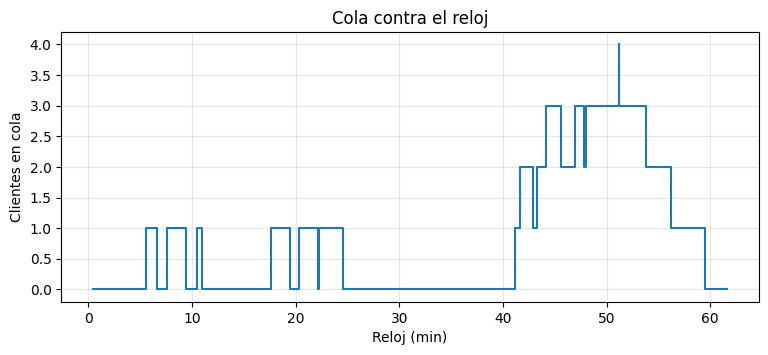

In [5]:
def graficar_cola(tabla, titulo='Cola contra el reloj'):
    plt.figure(figsize=(9, 3.5))
    plt.step(tabla['Reloj'], tabla['En cola'], where='post')
    plt.xlabel('Reloj (min)'); plt.ylabel('Clientes en cola'); plt.title(titulo)
    plt.grid(alpha=.3); plt.show()
graficar_cola(tabla3)

## 5. Dos métodos, mismo resultado


In [6]:
def espera_max_fin(llegadas, servicios):
    fin_prev, esperas = 0.0, []
    for a, s in zip(llegadas, servicios):
        ini = max(a, fin_prev)
        esperas.append(ini - a)
        fin_prev = ini + s
    return np.array(esperas)

e2 = espera_max_fin(llegadas, servicios)
print('Evento a evento :', round(c3['espera_prom'], 6))
print('max(llegada,fin):', round(e2.mean(), 6))
assert np.allclose(e2, c3['esperas'])

Evento a evento : 2.494633
max(llegada,fin): 2.494633


Ambos métodos dan los mismos tiempos de espera porque con un solo servidor y cola FIFO, cada cliente empieza cuando llega o cuando el servidor termina con el anterior, lo que ocurra después.

# Parte B · Actividad 11
> Los ejercicios 1 y 2 usan datos del notebook original (6 clientes) que no vienen en el PDF. Lo demás está resuelto con los parámetros del laboratorio; ajústalos si el notebook indica otros.

## Ejercicio 2. Validar el algoritmo

In [7]:
llegadas_b1 = [0, 2, 3, 3, 7, 9]      # PLACEHOLDER: datos del ejercicio 1
servicios_b1 = [3, 2, 2, 3, 2, 1]     # PLACEHOLDER
tb1, cb1 = simular(llegadas_b1, servicios_b1)
print(tb1)
print({k: round(v, 3) for k, v in cb1.items() if k != 'esperas'})
# assert con los valores que obtuviste a mano, por ejemplo:
# assert cb1['atendidos'] == 6 and abs(cb1['espera_prom'] - TU_VALOR) < 1e-9

    Reloj   Evento Cliente  En cola Servidor Próx. salida
0       0  Llegada       1        0  Ocupado            3
1       2  Llegada       2        1  Ocupado            3
2       3   Salida                0  Ocupado            5
3       3  Llegada       3        1  Ocupado            5
4       3  Llegada       4        2  Ocupado            5
5       5   Salida                1  Ocupado            7
6       7   Salida                0  Ocupado           10
7       7  Llegada       5        1  Ocupado           10
8       9  Llegada       6        2  Ocupado           10
9      10   Salida                1  Ocupado           12
10     12   Salida                0  Ocupado           13
11     13   Salida                0    Libre            -
{'atendidos': 6, 'espera_prom': np.float64(2.167), 'ocupacion': 1.0, 'cola_max': 2, 'cola_prom': 1.0, 'tiempo_sistema_prom': np.float64(4.333), 'esperaron_mas_5': 0, 'tiempo_final': 13}


## Ejercicio 3. 50 clientes: espera promedio, ocupación, cola máxima y gráfica

Espera promedio: 2.110 min
Ocupación      : 81.8%
Cola máxima    : 4


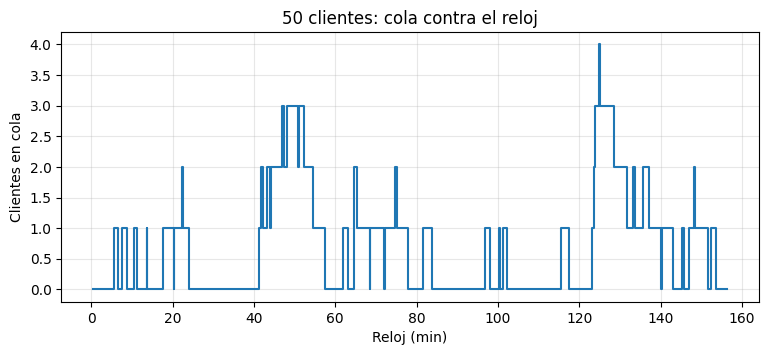

In [8]:
rng = np.random.default_rng(2026)
llegadas3 = np.cumsum(rng.exponential(3, 50))
servicios3 = rng.uniform(1.5, 3.5, 50)
tb3, cb3 = simular(llegadas3, servicios3)
print(f"Espera promedio: {cb3['espera_prom']:.3f} min")
print(f"Ocupación      : {cb3['ocupacion']:.1%}")
print(f"Cola máxima    : {cb3['cola_max']}")
graficar_cola(tb3, '50 clientes: cola contra el reloj')

## Ejercicio 4. Contadores nuevos
Tiempo promedio en el sistema (espera + servicio) y clientes que esperaron más de 5 minutos (ya los calcula `simular`).

In [9]:
print(f"Tiempo promedio en el sistema: {cb3['tiempo_sistema_prom']:.3f} min")
print(f"Clientes que esperaron > 5 min: {cb3['esperaron_mas_5']} de {cb3['atendidos']}")

Tiempo promedio en el sistema: 4.667 min
Clientes que esperaron > 5 min: 6 de 50


## Ejercicio 5. Modelo continuo: nivel de la fila con `dt = 0.1`


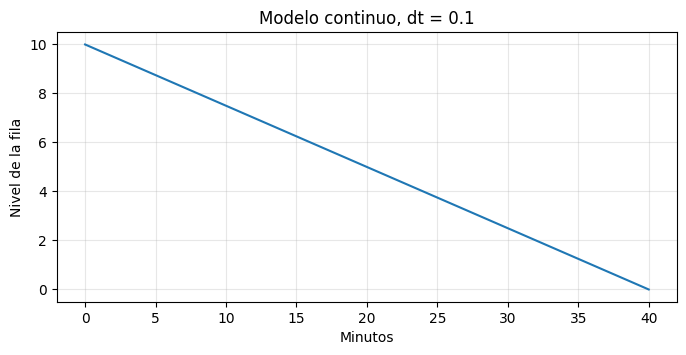

La fila se vacía en el minuto 40.0


In [10]:
def nivel_fila(L0, tasa_entrada, tasa_salida, dt, t_max=600):
    t, L = 0.0, float(L0)
    ts, Ls = [t], [L]
    while t < t_max and L > 0:
        L = max(0.0, L + (tasa_entrada - tasa_salida) * dt)
        t = round(t + dt, 10)
        ts.append(t); Ls.append(L)
    return np.array(ts), np.array(Ls)

L0, lam, mu = 10, 1/4, 1/2          # TODO: datos del notebook (clientes, 1/min, 1/min)
t01, L01 = nivel_fila(L0, lam, mu, 0.1)
plt.figure(figsize=(8, 3.5)); plt.plot(t01, L01)
plt.xlabel('Minutos'); plt.ylabel('Nivel de la fila'); plt.title('Modelo continuo, dt = 0.1'); plt.grid(alpha=.3); plt.show()
print('La fila se vacía en el minuto', t01[-1])

**Comparación (con tus palabras):** el modelo continuo suaviza la fila (acepta fracciones de cliente y usa tasas promedio); el discreto muestra saltos de 1 en 1 y depende de los tiempos aleatorios de cada corrida.

# Parte C · Actividad 12
Escenario (ej. 1 a 4): 30 clientes por corrida, llegadas exponenciales con media 4 min, servicio uniforme entre 2 y 5 min. El generador se crea una sola vez al inicio de cada ejercicio.

## Ejercicio 1. Estructura completa del programa
Bloques: (1) parámetros, (2) generación de tiempos, (3) simulación, (4) medidas de desempeño, (5) reporte.

In [11]:
# Bloque 1: parámetros
N_CLIENTES, MEDIA_LLEGADA, SERV_MIN, SERV_MAX = 30, 4, 2, 5

# Bloque 2: generación de tiempos
def generar(rng, servicio='uniforme'):
    llegadas = np.cumsum(rng.exponential(MEDIA_LLEGADA, N_CLIENTES))
    if servicio == 'uniforme':
        servicios = rng.uniform(SERV_MIN, SERV_MAX, N_CLIENTES)
    else:   # exponencial con la misma media (3.5 min)
        servicios = rng.exponential((SERV_MIN + SERV_MAX) / 2, N_CLIENTES)
    return llegadas, servicios

# Bloque 3 y 4: simulación + medidas
def una_corrida(rng, servicio='uniforme'):
    ll, sv = generar(rng, servicio)
    tabla, c = simular(ll, sv)
    return tabla, c

# Bloque 5: reporte
rng = np.random.default_rng(2026)
tabla_c1, c_c1 = una_corrida(rng)
print(f"Espera promedio: {c_c1['espera_prom']:.3f} min")
print(f"Ocupación      : {c_c1['ocupacion']:.1%}")
print(f"Cola máxima    : {c_c1['cola_max']}")

Espera promedio: 3.401 min
Ocupación      : 86.5%
Cola máxima    : 3


## Ejercicio 2. Una corrida no basta: 10 corridas

In [12]:
rng = np.random.default_rng(2026)
esp10 = [una_corrida(rng)[1]['espera_prom'] for _ in range(10)]
print('Esperas promedio:', np.round(esp10, 3))
print(f'Menor: {min(esp10):.3f} min   Mayor: {max(esp10):.3f} min')

Esperas promedio: [3.401 5.241 5.395 7.216 5.193 2.466 7.466 6.044 3.658 2.095]
Menor: 2.095 min   Mayor: 7.466 min


Las corridas dan resultados muy distintos solo por azar; una sola no representa el comportamiento del sistema.

## Ejercicio 3. Análisis de 500 corridas
Ejecute 500 corridas y guarde las tres medidas de cada corrida en un DataFrame.
Reporte la media y el margen de error de cada medida.
Grafique el histograma de la espera promedio.
Explique en dos líneas por qué la mediana de la espera promedio es menor que su media.


Espera promedio (min)    media = 5.832  ± 0.337
Ocupación                media = 0.808  ± 0.009
Cola máxima              media = 4.776  ± 0.171


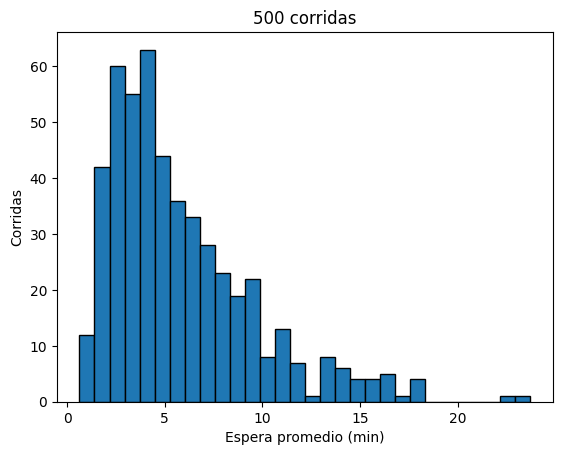

In [13]:
def margen(x):
    x = np.asarray(x)
    return 2 * x.std(ddof=1) / np.sqrt(len(x))

def muchas(n_corridas, servicio='uniforme'):
    rng = np.random.default_rng(2026)
    out = [una_corrida(rng, servicio)[1] for _ in range(n_corridas)]
    return (np.array([o['espera_prom'] for o in out]),
            np.array([o['ocupacion'] for o in out]),
            np.array([o['cola_max'] for o in out]))

esp, ocu, cmax = muchas(500)
for nombre, x in [('Espera promedio (min)', esp), ('Ocupación', ocu), ('Cola máxima', cmax)]:
    print(f'{nombre:24s} media = {x.mean():.3f}  ± {margen(x):.3f}')
plt.hist(esp, bins=30, edgecolor='k'); plt.xlabel('Espera promedio (min)'); plt.ylabel('Corridas')
plt.title('500 corridas'); plt.show()

## Ejercicio 4. Comparación de escenarios
Compare el servicio uniforme entre 2 y 5 minutos contra un servicio exponencial con el mismo promedio: `rng.exponential(scale=3.5, size=30)`.
1. Ejecute 500 corridas de cada escenario, cada uno con su propio generador `np.random.default_rng(2026)`.
2. Reporte en una tabla la media y el margen de las tres medidas para ambos escenarios.
3. Grafique en una misma figura los histogramas de la espera promedio de los dos escenarios, uno encima del otro (use `alpha=0.5` para que se vean los dos).
4. Responda: ¿los rangos de la espera promedio se enciman? ¿La diferencia es real? Justifique con sus números.

Espera     uniforme 5.832 ± 0.337 | exponencial 8.566 ± 0.599
Ocupación  uniforme 0.808 ± 0.009 | exponencial 0.772 ± 0.012
Cola máx.  uniforme 4.776 ± 0.171 | exponencial 6.254 ± 0.262


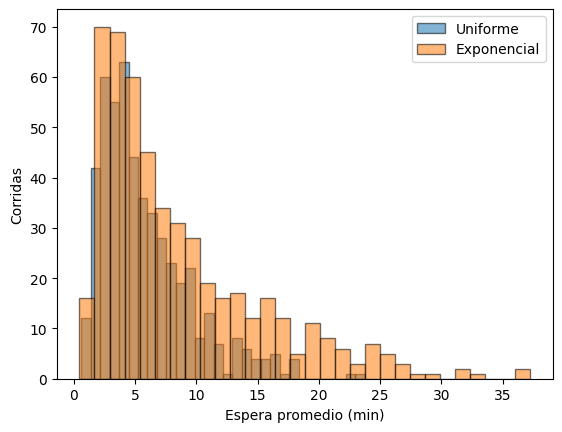

In [14]:
esp_u, ocu_u, cm_u = muchas(500, 'uniforme')
esp_e, ocu_e, cm_e = muchas(500, 'exponencial')
for nombre, a, b in [('Espera', esp_u, esp_e), ('Ocupación', ocu_u, ocu_e), ('Cola máx.', cm_u, cm_e)]:
    print(f'{nombre:10s} uniforme {a.mean():.3f} ± {margen(a):.3f} | exponencial {b.mean():.3f} ± {margen(b):.3f}')
plt.hist(esp_u, bins=30, alpha=.55, label='Uniforme', edgecolor='k')
plt.hist(esp_e, bins=30, alpha=.55, label='Exponencial', edgecolor='k')
plt.xlabel('Espera promedio (min)'); plt.ylabel('Corridas'); plt.legend(); plt.show()

**Interpretación:** con la misma media, el servicio exponencial tiene más variabilidad (hay servicios muy largos), por lo que produce esperas promedio mayores y más dispersas.

## Ejercicio 5. La fila como nivel continuo
Modele la fila de la ventanilla como un nivel continuo, sin contar clientes uno por uno, con un reloj de paso fijo. El nivel inicial es 0.

Del minuto 0 al 10 entran 0.5 y salen 0.3 clientes por minuto.
Del minuto 10 al 20 entran 0.2 y salen 0.5 clientes por minuto.
Programe el modelo con un ciclo for, dt = 1 y la regla nivel = max(0, nivel + (entra - sale) * dt). Guarde en un DataFrame el minuto y el nivel de cada paso.
Reporte el nivel en los minutos 10 y 20, y el minuto en que la fila se vacía.
Grafique el nivel contra el tiempo.
Repita con dt = 0.1 y reporte de nuevo el minuto en que la fila se vacía. Explique en dos líneas por qué cambia.
Explique en dos líneas qué pasaría sin max(0, ...) y por qué ese resultado no tiene sentido.

dt = 1: la fila se vacía en el minuto 40.0
dt = 0.1: la fila se vacía en el minuto 40.0


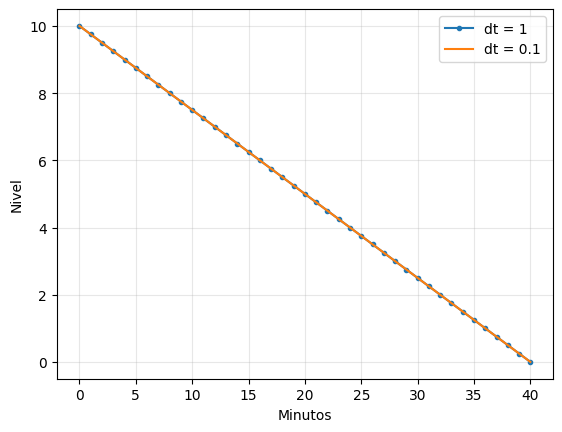

In [15]:
L0, lam, mu = 10, 1/4, 1/2
for dt in (1, 0.1):
    t, L = nivel_fila(L0, lam, mu, dt)
    print(f'dt = {dt}: la fila se vacía en el minuto {t[-1]:.1f}')
t1, L1 = nivel_fila(L0, lam, mu, 1); t2, L2 = nivel_fila(L0, lam, mu, 0.1)
plt.plot(t1, L1, 'o-', ms=3, label='dt = 1'); plt.plot(t2, L2, label='dt = 0.1')
plt.xlabel('Minutos'); plt.ylabel('Nivel'); plt.legend(); plt.grid(alpha=.3); plt.show()

**Respuesta:**

## Ejercicio 6. ¿Discreto o continuo?
**Respuestas:** 1.-Discreto:Si el estado cambia en instantes concretos por eventos que se cuentan 2.-Cntinuo:El nivel y caudal varían de forma fluida 3.-Discreto:Llegada y atención de clientes específicos 4.-Continuo:Proceso de absorción y degradación química 5.-Discreto:Cuando se llena por la tuberia y el consumo en la casa,se modelan típicamente mediante ecuaciones diferenciales o tasas de cambio continuas